In [1]:
import numpy as np
import pandas as pd 
from scipy import stats
import yfinance as yf
from datetime import datetime, timedelta

In [ ]:


# 1. Download dei dati
df_asset = yf.download('AAPL', start='2014-01-01', end='2025-01-01')
df_rf = yf.download('^IRX', start='2014-01-01', end='2025-01-01')
df_market = yf.download('^GSPC', start='2014-01-01', end='2025-01-01')

# Salvataggio iniziale
df_asset.to_csv("AAPL_data.csv")
df_rf.to_csv("AAPL_rf_data.csv")
df_market.to_csv("AAPL_market_data.csv")


def load_csv(path):
    df = pd.read_csv(path, index_col=0)
    # Rimuove eventuali righe intestazione extra di yfinance
    df = df[pd.to_datetime(df.index, errors="coerce", utc=True).notna()]
    # Converte l'indice in Datetime senza timezone
    df.index = pd.to_datetime(df.index, utc=True).tz_localize(None)
    df.index.name = "Date"
    return df.apply(pd.to_numeric, errors="coerce")


# 2. Caricamento pulito
df_asset = load_csv("AAPL_data.csv")
df_rf = load_csv("AAPL_rf_data.csv")
df_market = load_csv("AAPL_market_data.csv")


# 3. Calcolo rendimenti mensili
def monthly_returns(df):
    df = df.resample('ME').last()  # O 'M' a seconda della versione di pandas
    df['Monthly Return'] = df['Close'].pct_change()
    return df


df_asset = monthly_returns(df_asset)
df_market = monthly_returns(df_market)

# Per il Risk-Free: Tasso annuo in % -> Tasso mensile in decimali
df_rf = df_rf.resample('ME').last() / 100 / 12
df_rf['Monthly Return'] = df_rf['Close']

# 4. Selezione e Rinomina colonne
df_asset = df_asset[['Monthly Return']].rename(columns={'Monthly Return': 'Ri_AAPL'})
df_market = df_market[['Monthly Return']].rename(columns={'Monthly Return': 'RM'})
df_rf = df_rf[['Monthly Return']].rename(columns={'Monthly Return': 'RF'})

# 5. Merge e rimozione dei valori NaN iniziali
df_merged = df_asset.join([df_rf, df_market], how='inner').dropna()

# Stampa di controllo
print("Colonne create:", df_merged.columns.tolist())
print(df_merged.head())

# Salvataggio finale per la regressione
df_merged.to_csv("dataset.csv")

In [34]:
df = pd.read_csv("dataset.csv", index_col=0)


def CAPM(x, y):
    n = len(y)
    beta = np.sum((x - np.mean(x)) * (y - np.mean(y))) / np.sum((x - np.mean(x)) ** 2)
    alfa = np.mean(y) - beta * np.mean(x)
    print("Beta:", beta)
    print("Alpha:", alfa)
    return beta, alfa


x = df['RM'] - df['RF']
y = df['Ri_AAPL'] - df['RF']

capm = CAPM(x, y)

Beta: 1.2321094082643695
Alpha: 0.012303771029588798


# Metrics

In [35]:
def t_test(capm, x, y):
    n = len(y)
    beta, alfa = capm
    resid = y - (alfa + beta * x)
    S = np.sum(resid ** 2) / (n - 2)
    sd_beta = np.sqrt(S/(np.sum((x - np.mean(x)) ** 2)))
    t_stat = beta / sd_beta
    p_value = 2*(1 - stats.t.cdf(np.abs(t_stat), df=n-2))
    if beta - 2.002*sd_beta < 0 and beta + 2.002*sd_beta > 0:
        print("Beta is not statistically significant")
        return False, float(p_value), float(sd_beta)
    else:
        print("Beta is statistically significant")
        return True, float(p_value), float(sd_beta)


def r_squared(x, y, capm):
    beta, alfa = capm
    y_hat = alfa + beta * x
    ss_total = np.sum((y - np.mean(y)) ** 2)
    ss_residual = np.sum((y - y_hat) ** 2)
    r2 = 1 - (ss_residual / ss_total)
    return r2


def f_test():
    pass


print("T-test result:", t_test(capm, x, y))
print("R-squared:", r_squared(x, y, capm))

Beta is statistically significant
T-test result: (True, 0.0, 0.1186439076611535)
R-squared: 0.45534435796911166


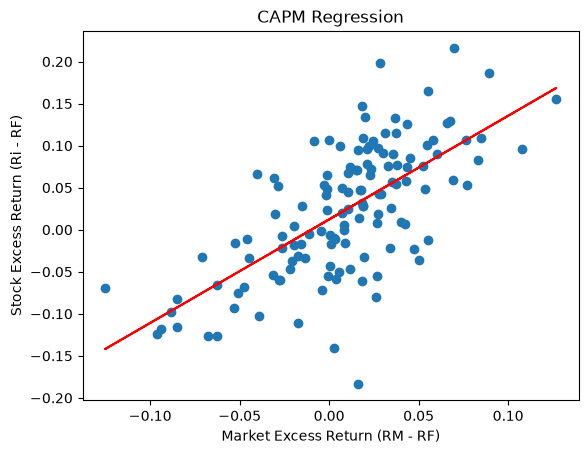

In [36]:
import matplotlib.pyplot as plt

x_2 = df['RM'] - df['RF']

y_2 = df['Ri_AAPL'] - df['RF']

y = capm[1] + capm[0] * x_2

plt.scatter(x_2, y_2, label='Data points')
plt.plot(x_2, y, color='red', label='CAPM line')
plt.xlabel('Market Excess Return (RM - RF)')
plt.ylabel('Stock Excess Return (Ri - RF)')
plt.title('CAPM Regression')
plt.show()